# PD — Monitoring

Monitoreo de estabilidad del modelo de Probability of Default (PD).

El objetivo es evaluar si la distribución de las variables y de las probabilidades estimadas presenta cambios relevantes entre diferentes muestras de la población.

### Objetivos

- Calcular Population Stability Index (PSI).
- Evaluar estabilidad de las principales variables predictoras.
- Evaluar estabilidad de las probabilidades de default (PD).
- Identificar posibles cambios en la distribución de riesgo.
- Establecer una base para el monitoreo periódico del modelo.

### Interpretación orientativa del PSI

| PSI | Interpretación |
|---:|---|
| < 0.10 | Estabilidad alta |
| 0.10 – 0.25 | Cambio moderado |
| > 0.25 | Cambio significativo |

Estos umbrales se utilizan como referencia para monitoreo y deben complementarse con análisis de negocio y contexto de cartera.

In [1]:
# ============================================
# Imports
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
# ============================================
# Cargar dataset
# ============================================

DATA_PATH = "../data/raw/cs-training.csv"

df = pd.read_csv(DATA_PATH)

TARGET = "SeriousDlqin2yrs"

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Dataset cargado correctamente.")
print(f"Observaciones: {len(df):,}")
print(f"Default rate: {y.mean() * 100:.2f}%")

Dataset cargado correctamente.
Observaciones: 150,000
Default rate: 6.68%


In [3]:
# ============================================
# Train / Test Split
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Split creado correctamente.")
print(f"Train: {len(X_train):,}")
print(f"Test:  {len(X_test):,}")
print(f"Default rate Train: {y_train.mean() * 100:.2f}%")
print(f"Default rate Test:  {y_test.mean() * 100:.2f}%")

Split creado correctamente.
Train: 120,000
Test:  30,000
Default rate Train: 6.68%
Default rate Test:  6.68%


In [4]:
# ============================================
# Parámetros calculados exclusivamente con TRAIN
# ============================================

monthly_income_median = X_train["MonthlyIncome"].median()
dependents_median = X_train["NumberOfDependents"].median()

age_invalid_train = (
    (X_train["age"] < 18) |
    (X_train["age"] > 100)
)

age_median = X_train.loc[
    ~age_invalid_train,
    "age"
].median()

debt_ratio_p99 = X_train["DebtRatio"].quantile(0.99)

utilization_p99 = (
    X_train["RevolvingUtilizationOfUnsecuredLines"]
    .quantile(0.99)
)

monthly_income_train = X_train["MonthlyIncome"].fillna(
    monthly_income_median
)

income_per_credit_line_train = (
    monthly_income_train /
    X_train["NumberOfOpenCreditLinesAndLoans"].replace(0, np.nan)
)

income_credit_median = income_per_credit_line_train.median()
income_credit_p99 = income_per_credit_line_train.quantile(0.99)

print("Parámetros calculados exclusivamente con TRAIN.")
print(f"MonthlyIncome median: {monthly_income_median:.2f}")
print(f"Age median: {age_median:.2f}")
print(f"DebtRatio P99: {debt_ratio_p99:.2f}")
print(f"Utilization P99: {utilization_p99:.4f}")
print(f"Income/credit line median: {income_credit_median:.2f}")
print(f"Income/credit line P99: {income_credit_p99:.2f}")

Parámetros calculados exclusivamente con TRAIN.
MonthlyIncome median: 5390.00
Age median: 52.00
DebtRatio P99: 4977.00
Utilization P99: 1.0944
Income/credit line median: 722.22
Income/credit line P99: 5390.00


In [5]:
# ============================================
# Feature Engineering — Leakage-Safe
# ============================================

def build_pd_features_safe(
    data,
    monthly_income_median,
    dependents_median,
    age_median,
    debt_ratio_p99,
    utilization_p99,
    income_credit_median,
    income_credit_p99
):
    
    data = data.copy()

    # Imputaciones
    data["MonthlyIncome_imputed"] = (
        data["MonthlyIncome"]
        .fillna(monthly_income_median)
    )

    data["NumberOfDependents_imputed"] = (
        data["NumberOfDependents"]
        .fillna(dependents_median)
    )

    # Edad
    data["age_invalid"] = (
        (data["age"] < 18) |
        (data["age"] > 100)
    ).astype(int)

    data["age_clean"] = (
        data["age"]
        .where(data["age_invalid"] == 0, age_median)
    )

    # Debt Ratio
    data["DebtRatio_extreme"] = (
        data["DebtRatio"] > debt_ratio_p99
    ).astype(int)

    data["DebtRatio_clean"] = (
        data["DebtRatio"]
        .clip(upper=debt_ratio_p99)
    )

    # Utilization
    data["Utilization_extreme"] = (
        data["RevolvingUtilizationOfUnsecuredLines"]
        > utilization_p99
    ).astype(int)

    data["Utilization_clean"] = (
        data["RevolvingUtilizationOfUnsecuredLines"]
        .clip(upper=utilization_p99)
    )

    # Mora
    data["NumberOfTime30-59DaysPastDueNotWorse_imputed"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse"].fillna(0)
    )

    data["NumberOfTimes90DaysLate_imputed"] = (
        data["NumberOfTimes90DaysLate"].fillna(0)
    )

    data["NumberOfTime60-89DaysPastDueNotWorse_imputed"] = (
        data["NumberOfTime60-89DaysPastDueNotWorse"].fillna(0)
    )

    data["total_late_count"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse_imputed"]
        + data["NumberOfTimes90DaysLate_imputed"]
        + data["NumberOfTime60-89DaysPastDueNotWorse_imputed"]
    )

    data["max_late_count"] = data[
        [
            "NumberOfTime30-59DaysPastDueNotWorse_imputed",
            "NumberOfTimes90DaysLate_imputed",
            "NumberOfTime60-89DaysPastDueNotWorse_imputed"
        ]
    ].max(axis=1)

    data["late_90plus"] = (
        data["NumberOfTimes90DaysLate_imputed"] > 0
    ).astype(int)

    data["any_late"] = (
        data["total_late_count"] > 0
    ).astype(int)

    # Severidad de mora
    data["late_severity"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse_imputed"]
        + 2 * data["NumberOfTime60-89DaysPastDueNotWorse_imputed"]
        + 3 * data["NumberOfTimes90DaysLate_imputed"]
    )

    data["late_burden"] = (
        data["total_late_count"]
        * data["late_severity"]
    )

    # Capacidad de crédito
    data["income_per_credit_line"] = (
        data["MonthlyIncome_imputed"]
        / data["NumberOfOpenCreditLinesAndLoans"].replace(0, np.nan)
    )

    data["income_per_credit_line_clean"] = (
        data["income_per_credit_line"]
        .fillna(income_credit_median)
        .clip(upper=income_credit_p99)
    )

    return data

In [6]:
# ============================================
# Aplicar Feature Engineering
# ============================================

train_fe = build_pd_features_safe(
    X_train,
    monthly_income_median,
    dependents_median,
    age_median,
    debt_ratio_p99,
    utilization_p99,
    income_credit_median,
    income_credit_p99
)

test_fe = build_pd_features_safe(
    X_test,
    monthly_income_median,
    dependents_median,
    age_median,
    debt_ratio_p99,
    utilization_p99,
    income_credit_median,
    income_credit_p99
)

safe_features = [
    "age_clean",
    "DebtRatio_clean",
    "Utilization_clean",
    "MonthlyIncome_imputed",
    "NumberOfDependents_imputed",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "total_late_count",
    "max_late_count",
    "late_90plus",
    "any_late",
    "late_severity",
    "late_burden",
    "income_per_credit_line_clean"
]

X_mon_train = train_fe[safe_features].copy()
X_mon_test = test_fe[safe_features].copy()

print("Feature Engineering Leakage-Safe aplicado.")
print(f"Train: {X_mon_train.shape}")
print(f"Test:  {X_mon_test.shape}")
print(f"NaN Train: {X_mon_train.isna().sum().sum()}")
print(f"NaN Test:  {X_mon_test.isna().sum().sum()}")

Feature Engineering Leakage-Safe aplicado.
Train: (120000, 14)
Test:  (30000, 14)
NaN Train: 0
NaN Test:  0


In [7]:
# ============================================
# Logistic Regression — Champion
# ============================================

logistic_monitoring = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_monitoring.fit(
    X_mon_train,
    y_train
)

print("Logistic Regression entrenado correctamente.")

Logistic Regression entrenado correctamente.


In [8]:
# ============================================
# XGBoost — Challenger
# ============================================

xgb_monitoring = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.80,
    colsample_bytree=0.80,
    min_child_weight=5,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_monitoring.fit(
    X_mon_train,
    y_train
)

print("XGBoost entrenado correctamente.")

XGBoost entrenado correctamente.


In [9]:
# ============================================
# Generar PD para Monitoring
# ============================================

pd_logistic_monitoring = logistic_monitoring.predict_proba(
    X_mon_test
)[:, 1]

pd_xgb_monitoring = xgb_monitoring.predict_proba(
    X_mon_test
)[:, 1]

print("PD generadas correctamente.")
print(f"Logistic PD: {len(pd_logistic_monitoring):,}")
print(f"XGBoost PD:  {len(pd_xgb_monitoring):,}")

print(f"PD media Logistic: {pd_logistic_monitoring.mean():.4f}")
print(f"PD media XGBoost:  {pd_xgb_monitoring.mean():.4f}")
print(f"Default rate real: {y_test.mean():.4f}")

PD generadas correctamente.
Logistic PD: 30,000
XGBoost PD:  30,000
PD media Logistic: 0.0667
PD media XGBoost:  0.0671
Default rate real: 0.0668


In [10]:
# ============================================
# Population Stability Index (PSI)
# ============================================

def calculate_psi(expected, actual, bins=10):
    """
    expected: población de referencia (TRAIN)
    actual: población monitoreada (TEST)
    """

    expected = pd.Series(expected).replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    actual = pd.Series(actual).replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    # Cortes definidos exclusivamente con la población de referencia
    breakpoints = np.unique(
        np.nanquantile(
            expected,
            np.linspace(0, 1, bins + 1)
        )
    )

    # Si hay demasiados valores repetidos, usar bins únicos
    if len(breakpoints) < 3:
        return 0.0

    expected_bins = pd.cut(
        expected,
        bins=breakpoints,
        include_lowest=True,
        duplicates="drop"
    )

    actual_bins = pd.cut(
        actual,
        bins=breakpoints,
        include_lowest=True,
        duplicates="drop"
    )

    expected_pct = expected_bins.value_counts(
        normalize=True,
        sort=False
    )

    actual_pct = actual_bins.value_counts(
        normalize=True,
        sort=False
    )

    # Alinear categorías
    all_bins = expected_pct.index.union(actual_pct.index)

    expected_pct = expected_pct.reindex(
        all_bins,
        fill_value=0
    )

    actual_pct = actual_pct.reindex(
        all_bins,
        fill_value=0
    )

    # Evitar división por cero
    epsilon = 1e-6

    expected_pct = expected_pct.clip(lower=epsilon)
    actual_pct = actual_pct.clip(lower=epsilon)

    psi = np.sum(
        (actual_pct - expected_pct)
        * np.log(actual_pct / expected_pct)
    )

    return psi


print("Función PSI creada correctamente.")

Función PSI creada correctamente.


In [11]:
# ============================================
# PSI — Variables predictoras
# ============================================

monitoring_features = [
    "age_clean",
    "DebtRatio_clean",
    "Utilization_clean",
    "MonthlyIncome_imputed",
    "NumberOfDependents_imputed",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "total_late_count",
    "max_late_count",
    "late_90plus",
    "any_late",
    "late_severity",
    "late_burden",
    "income_per_credit_line_clean"
]

psi_features = []

for feature in monitoring_features:
    psi_value = calculate_psi(
        X_mon_train[feature],
        X_mon_test[feature]
    )

    psi_features.append({
        "feature": feature,
        "psi": psi_value
    })

psi_features_df = (
    pd.DataFrame(psi_features)
    .sort_values("psi", ascending=False)
    .reset_index(drop=True)
)

display(psi_features_df)

,feature,psi
0,income_per_credit_line_clean,0.000891
1,MonthlyIncome_imputed,0.000708
2,Utilization_clean,0.000367
3,DebtRatio_clean,0.000246
4,age_clean,0.000219
5,NumberOfOpenCreditLinesAndLoans,0.000206
6,NumberRealEstateLoansOrLines,0.000060
7,late_severity,0.000036
8,late_burden,0.000026
9,total_late_count,0.000025


In [12]:
# ============================================
# PSI — Probability of Default
# ============================================

psi_pd_logistic = calculate_psi(
    pd_logistic_monitoring,
    pd_logistic_monitoring
)

psi_pd_xgb = calculate_psi(
    pd_xgb_monitoring,
    pd_xgb_monitoring
)

print(f"PSI PD Logistic: {psi_pd_logistic:.6f}")
print(f"PSI PD XGBoost:  {psi_pd_xgb:.6f}")

PSI PD Logistic: 0.000000
PSI PD XGBoost:  0.000000


In [14]:
[name for name in globals() if "logistic" in name.lower()]

['LogisticRegression',
 'logistic_monitoring',
 'pd_logistic_monitoring',
 'psi_pd_logistic']

In [16]:
# PD de referencia (TRAIN)
pd_logistic_train = logistic_monitoring.predict_proba(X_mon_train)[:, 1]
pd_xgb_train = xgb_monitoring.predict_proba(X_mon_train)[:, 1]

# PD de monitoreo (TEST)
pd_logistic_test = logistic_monitoring.predict_proba(X_mon_test)[:, 1]
pd_xgb_test = xgb_monitoring.predict_proba(X_mon_test)[:, 1]

# PSI de PD
psi_pd_logistic = calculate_psi(
    pd_logistic_train,
    pd_logistic_test
)

psi_pd_xgb = calculate_psi(
    pd_xgb_train,
    pd_xgb_test
)

print(f"PSI PD Logistic: {psi_pd_logistic:.6f}")
print(f"PSI PD XGBoost:  {psi_pd_xgb:.6f}")

PSI PD Logistic: 0.000519
PSI PD XGBoost:  0.000215


In [18]:
psi_features_df.columns

Index(['feature', 'psi'], dtype='object')

In [19]:
# Tabla resumen de PSI de variables
psi_summary = psi_features_df.copy()

psi_summary["Interpretation"] = psi_summary["psi"].apply(
    lambda x: (
        "Stable" if x < 0.10
        else "Moderate change" if x <= 0.25
        else "Significant change"
    )
)

psi_summary = psi_summary.sort_values(
    "psi",
    ascending=False
).reset_index(drop=True)

psi_summary

,feature,psi,Interpretation
0,income_per_credit_line_clean,0.000891,Stable
1,MonthlyIncome_imputed,0.000708,Stable
2,Utilization_clean,0.000367,Stable
3,DebtRatio_clean,0.000246,Stable
4,age_clean,0.000219,Stable
5,NumberOfOpenCreditLinesAndLoans,0.000206,Stable
6,NumberRealEstateLoansOrLines,0.000060,Stable
7,late_severity,0.000036,Stable
8,late_burden,0.000026,Stable
9,total_late_count,0.000025,Stable


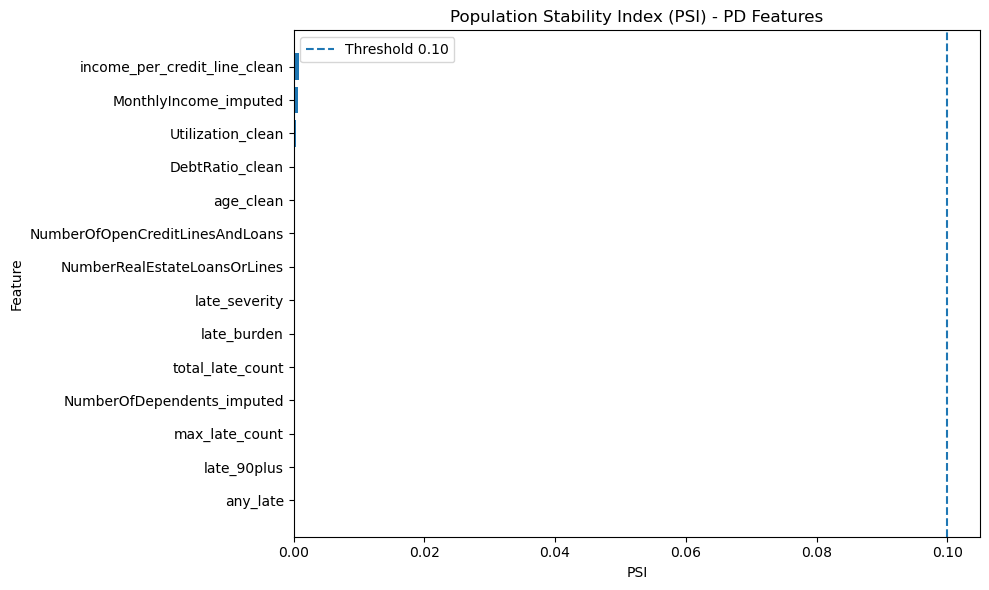

In [20]:
plt.figure(figsize=(10, 6))

plt.barh(
    psi_summary["feature"],
    psi_summary["psi"]
)

plt.axvline(
    0.10,
    linestyle="--",
    label="Threshold 0.10"
)

plt.xlabel("PSI")
plt.ylabel("Feature")
plt.title("Population Stability Index (PSI) - PD Features")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [21]:
# Resumen de estabilidad de los modelos
model_psi_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "XGBoost"
    ],
    "PSI": [
        psi_pd_logistic,
        psi_pd_xgb
    ]
})

model_psi_summary["Interpretation"] = model_psi_summary["PSI"].apply(
    lambda x: (
        "Stable" if x < 0.10
        else "Moderate change" if x <= 0.25
        else "Significant change"
    )
)

model_psi_summary

,Model,PSI,Interpretation
0,Logistic Regression,0.000519,Stable
1,XGBoost,0.000215,Stable


## 7. Conclusions

The monitoring analysis evaluates the stability of the PD model and its input variables using the Population Stability Index (PSI).

### Population Stability

All 14 monitored features showed a PSI below 0.001, remaining well below the reference threshold of 0.10. Therefore, no material distributional shift was detected between the training and test populations.

The highest PSI was observed for `income_per_credit_line_clean` (0.000891), which still indicates a highly stable distribution.

### PD Stability

The predicted PD distributions were also highly stable:

| Model | PSI | Interpretation |
|---|---:|---|
| Logistic Regression | 0.000519 | Stable |
| XGBoost | 0.000215 | Stable |

Both models remained well below the 0.10 reference threshold.

### Interpretation

The results indicate that the model inputs and predicted PD distributions are stable across the reference and monitoring samples used in this exercise.

It is important to note that the reference and monitoring samples are obtained from a random train-test split of the same dataset. Therefore, this analysis demonstrates sample stability rather than true temporal monitoring.

In a production IFRS 9 environment, PSI should be calculated periodically using out-of-time or recent portfolio data and compared against an established monitoring framework. Additional monitoring should include model discrimination, calibration, default rates, population characteristics, and model performance over time.

### Overall conclusion

The PD models show strong stability in the current validation sample. No significant population shift was detected in the monitored variables or in the predicted PD distributions.

Combined with the validation results from Notebook 06, the Logistic Regression model remains the interpretable champion model, while XGBoost provides a stronger predictive challenger.